# Task 1 — Forecasting Across Heterogeneous Sensors

| Part                                       | I implemented                                   | Outputs |
| ------------------------------------------ | ----------------------------------------------- | ------- |
| 1. Context-Dependent Forecasting           | Raw Attention forecaster                        | 1.1–1.3 |
| 2. Separate Slow Structure from Repetition | `SeriesDecomposition.forward`                   | 2.1–2.3 |
| 3. Mix by Temporal Delay                   | `aggregate_delays` (`delay_scores` is supplied) | 3.1–3.2 |
| 4. Compare Designs and Deploy              | —                                               | 4.1–4.3 |


In [ ]:
# Kaggle setup: 
import os, shutil, glob
from pathlib import Path
os.environ["PA1_PRESET"] = os.environ.get("PA1_PRESET", "full")
if not Path("harness/design_controls.py").exists():
    found = glob.glob("/kaggle/input/**/harness/design_controls.py", recursive=True)
    if not found:
        raise FileNotFoundError("Attach the assignment zip as a Kaggle dataset (it must contain harness/).")
    shutil.copytree(Path(found[0]).parent, "harness", dirs_exist_ok=True)
print("preset =", os.environ["PA1_PRESET"], "| harness ready")

preset = full | harness ready


In [3]:
import os
import math
import sys
from pathlib import Path

for candidate in (Path("harness"), Path("PA 01/harness"), Path("../harness")):
    if candidate.is_dir():
        sys.path.insert(0, str(candidate.resolve()))
        break
else:
    raise FileNotFoundError("Keep harness/ beside this notebook and start Jupyter there.")

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
import design_controls as design
import design_data as data
import design_diagnostics as figures
import design_reporting as report

preset = os.environ.get("PA1_PRESET", "smoke")
seed = int(os.environ.get("PA1_SEED", "0"))
model_seed = int(os.environ.get("PA1_MODEL_SEED", str(seed)))
study = design.Study(preset, seed, model_seed=model_seed)
assert design.check_world(study.world)
print(f"preset={preset}; data seed={seed}; model seed={model_seed}; device={design.device}")
print(f"sampling rate={data.SAMPLING_RATE_HZ:g} Hz; products={', '.join(study.world.product_names)}")
print(f"product pace ranges={study.world.product_period_bands.tolist()} samples; "
      f"established stations={study.established.sum()}; held-out station=4")
print(f"eligible train/validation/test origins: "
      f"{len(study.region('train')['origins'])}/"
      f"{len(study.region('validation')['origins'])}/"
      f"{len(study.region('test')['origins'])}")



Four-station product-line world checks passed.
preset=full; data seed=0; model seed=0; device=cuda
sampling rate=20 Hz; products=Product A, Product B, Product C
product pace ranges=[[14.0, 18.0], [21.0, 27.0], [28.0, 36.0]] samples; established stations=3; held-out station=4
eligible train/validation/test origins: 650/105/105


## 1. Context-Dependent Forecasting


### Assemble the forecaster

At this point there is only one model: **Raw Attention**. It embeds the raw context, uses
Attention to mix positions, then predicts the next 48 readings.


In [4]:
class DenseAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads = heads
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.last_attention = None

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).transpose(1, 2)
                   for layer in (self.query, self.key, self.value))  # [B,h,L,d_h]
        weights = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)
        self.last_attention = weights.detach()  # [B,h,L,L]
        mixed = (weights @ v).transpose(1, 2).reshape(batch, length, width)
        return self.out(mixed)                  # [B,L,d]

class RawAttentionBlock(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):                       # [B,L,d]
        x = x + self.drop(self.mix(self.norm1(x)))
        return x + self.drop(self.feed_forward(self.norm2(x)))

class RawAttentionForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 dropout=0.1):
        super().__init__()
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([RawAttentionBlock(d, heads, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # context [B,L,1] -> return [B,H]
        # self.embed wants [B,1,L], then produces [B,d,L]. After transposing back, add
        # self.position, pass through every block and self.norm, flatten [B,L,d], and use
        # self.forecast_head to return [B,H].
        encoded = self.embed(context.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        return self.forecast_head(self.norm(encoded).flatten(1))
    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]



In [5]:
assert design.check_raw_attention_assembly(RawAttentionForecaster)
design.register_components(raw_forecaster_type=RawAttentionForecaster)


Raw-Attention assembly and gradient checks passed.


### Evidence

| Cell below                                       | Output |
| ------------------------------------------------ | ------ |
| fit Raw Attention, then compare four forecasters | 1.1    |
| the same station under two products              | 1.2    |
| Attention behaviour across two contexts          | 1.3    |


In [6]:
study.train("Raw Attention")
report.publish("1.1", report.comparison(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))


Raw Attention: 6000 steps, 75.6s, 368368 parameters, best established-validation MSE 0.192 (m/s²)² -- same physical units as the report tables below
Raw Attention: saved raw-attention-full-data0-model0-82d1f374c840.pt
Output 1.1


,model,established stations RMSE (m/s²),established stations MSE (m/s²)²,"established stations, Product A RMSE","established stations, Product B RMSE","established stations, Product C RMSE",held-out station 4 RMSE (m/s²),held-out station 4 MSE (m/s²)²,"held-out station 4, Product A RMSE","held-out station 4, Product B RMSE","held-out station 4, Product C RMSE",parameters,fit seconds
0,Shared ridge,0.767,0.588,0.805,0.854,0.621,0.876,0.767,0.909,0.982,0.713,4608,0.003
1,Sensor-specific ridge,0.768,0.590,0.804,0.852,0.630,unavailable,unavailable,unavailable,unavailable,unavailable,13824,0.085
2,Period-routed ridge,0.166,0.028,0.181,0.164,0.152,0.173,0.03,0.184,0.182,0.15,59904,0.014
3,Raw Attention,0.439,0.192,0.415,0.478,0.420,0.624,0.39,0.643,0.583,0.646,368368,75.604


Output 1.2


,station,product,actual period (samples),model,window RMSE (m/s²)
0,1,Product A,16.135,Shared ridge,0.779
1,1,Product A,16.135,Sensor-specific ridge,0.787
2,1,Product A,16.135,Period-routed ridge,0.232
3,1,Product A,16.135,Raw Attention,0.309
4,1,Product C,30.093,Shared ridge,0.448
5,1,Product C,30.093,Sensor-specific ridge,0.436
6,1,Product C,30.093,Period-routed ridge,0.150
7,1,Product C,30.093,Raw Attention,0.128


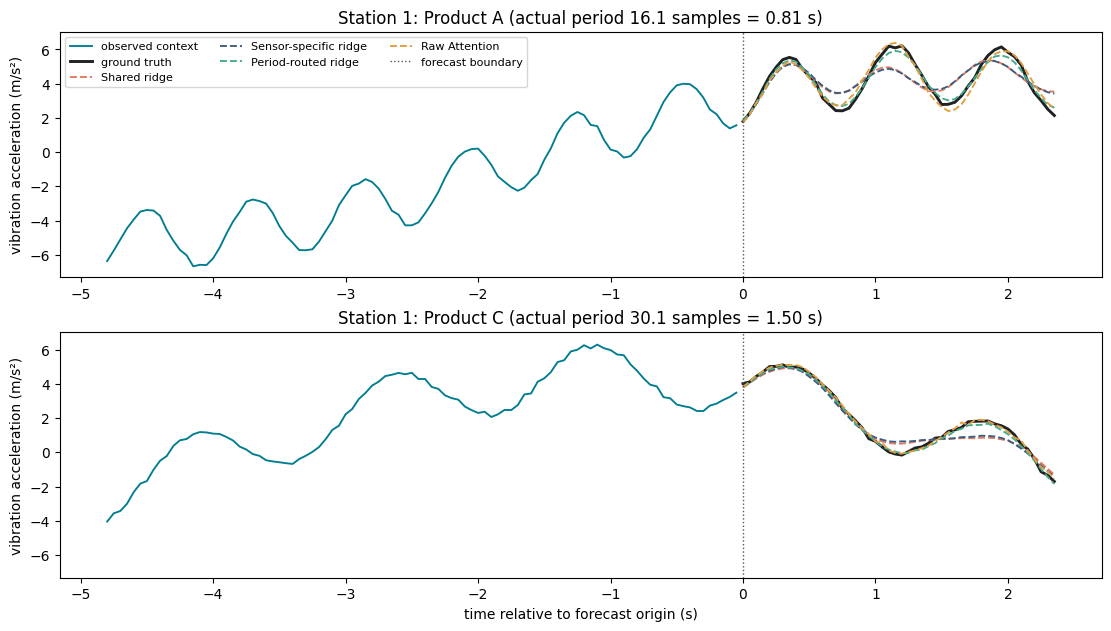

In [7]:
report.publish("1.2", figures.regime_forecasts(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))


Output 1.3


,station,product,actual period (samples),mean |Attention weight difference|,max |Attention weight difference|
0,1,Product A,16.135,unavailable,unavailable
1,1,Product C,30.093,unavailable,unavailable
2,1,Product A vs Product C (difference),unavailable,0.012,0.442


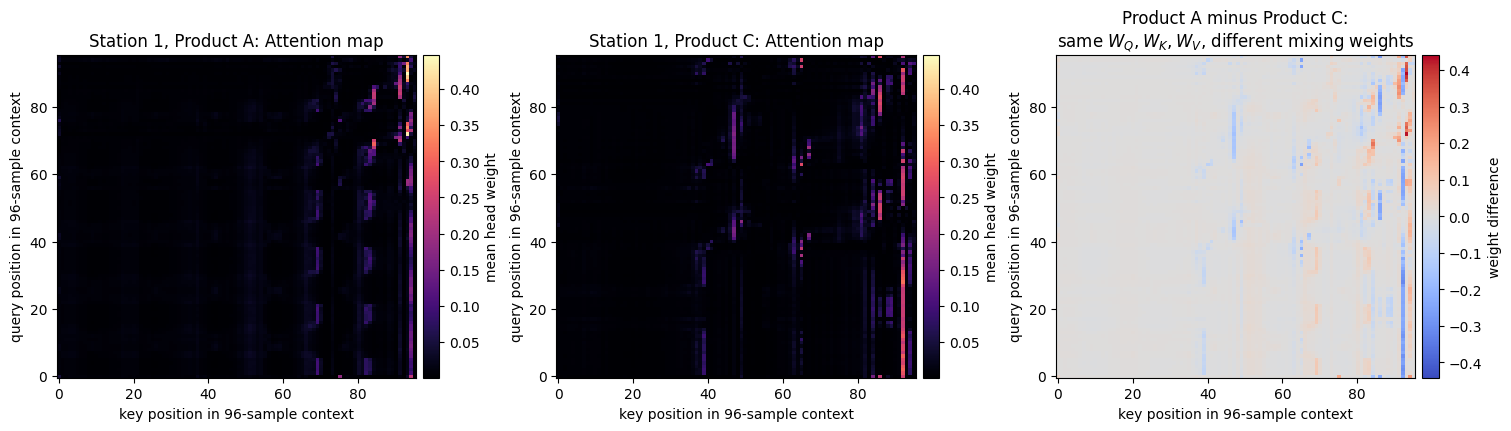

In [8]:
report.publish("1.3", figures.attention_behaviour(study))


## 2. Separate Slow Structure from Repetition

| Cell below                                              | Output |
| ------------------------------------------------------- | ------ |
| trend/residual for several candidate widths             | 2.1    |
| oracle primary-period recovery used to choose the width | 2.2    |
| decomposition ablation table and forecast shapes        | 2.3    |


In [ ]:
class SeriesDecomposition(nn.Module):
    def __init__(self, kernel):
        super().__init__()
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("kernel must be positive and odd")
        self.kernel = kernel

    def forward(self, x):                      
        half = self.kernel // 2
        padded = F.pad(x.transpose(1, 2), (half, half), mode="replicate")
        trend = F.avg_pool1d(padded, self.kernel, stride=1).transpose(1, 2)
        return x - trend, trend


In [ ]:
example = torch.tensor([1., 2., 3., 10., 5.]).reshape(1, 5, 1)
remainder, trend = SeriesDecomposition(3)(example)
display(pd.DataFrame({
    "x": example.flatten(),
    "your trend": trend.flatten(),
    "expected trend": [4 / 3, 2., 5., 6., 20 / 3],
    "your remainder": remainder.flatten(),
}).round(4))


,x,your trend,expected trend,your remainder
0,1.0,1.3333,1.3333,-0.3333
1,2.0,2.0000,2.0000,0.0000
2,3.0,5.0000,5.0000,-2.0000
3,10.0,6.0000,6.0000,4.0000
4,5.0,6.6667,6.6667,-1.6667


Decomposition checks passed.
Decomposed-Attention assembly and gradient checks passed.
Output 2.1


,width,selected,residual std (m/s²),trend range (m/s²)
0,17,False,0.578,8.768
1,25,False,1.012,8.037
2,33,False,1.372,8.076
3,41,True,1.572,8.280


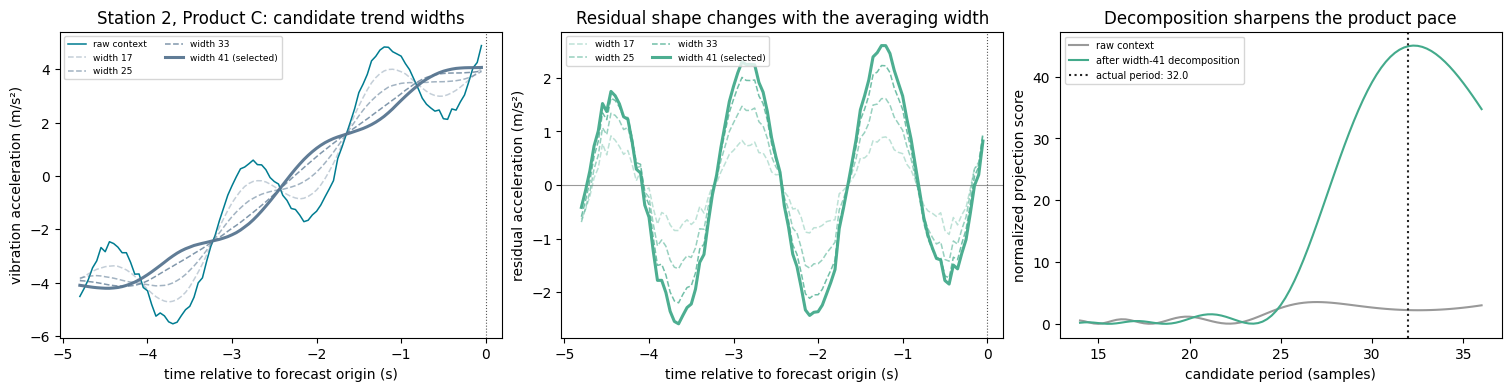

Output 2.2


,representation,oracle recovery within one sample,median absolute period error (samples),selected
0,raw,0.687,0.525,False
1,width 17,0.980,0.157,False
2,width 25,0.989,0.122,False
3,width 33,0.993,0.142,False
4,width 41,0.998,0.216,True


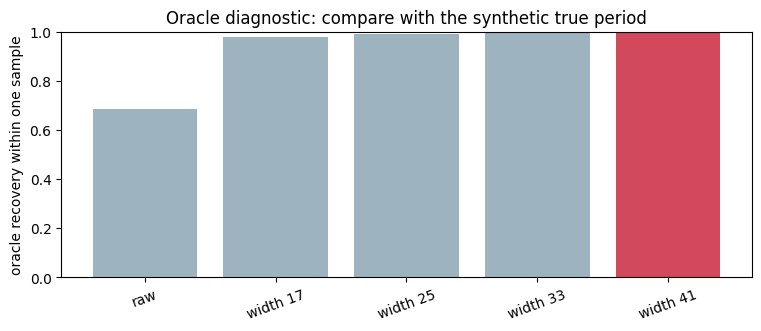

In [11]:
assert design.check_decomposition(SeriesDecomposition)
design.register_components(decomposition_type=SeriesDecomposition)

# Supplied Part 2 model: Attention mixes the remainder; a linear head forecasts the trend.
class DecompositionAttentionBlock(nn.Module):
    def __init__(self, d, heads, kernel, decomposition_type, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        self.strip1, self.strip2 = decomposition_type(kernel), decomposition_type(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class DecomposedAttentionForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 kernel=25, dropout=0.1, decomposition_type=None):
        super().__init__()
        self.split = decomposition_type(kernel)
        self.trend_head = nn.Linear(context, horizon)
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([DecompositionAttentionBlock(
            d, heads, kernel, decomposition_type, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        return seasonal_forecast + self.trend_head(trend.squeeze(-1))

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks]

assert design.check_decomposed_attention_assembly(DecomposedAttentionForecaster, SeriesDecomposition)
design.register_components(decomposed_attention_forecaster_type=DecomposedAttentionForecaster)
report.publish("2.1", figures.filter_decomposition(study))
report.publish("2.2", figures.recurrence_recovery(study))


Attention + decomposition: 6000 steps, 93.5s, 373024 parameters, best established-validation MSE 0.097 (m/s²)² -- same physical units as the report tables below
Attention + decomposition: saved attention-decomposition-full-data0-model0-020e48a7bbde.pt
Output 2.3


,model,population,product,MSE,RMSE (m/s²),MAE (m/s²)
0,Raw Attention,established,Product A,0.172,0.415,0.309
1,Raw Attention,established,Product B,0.228,0.478,0.352
2,Raw Attention,established,Product C,0.177,0.420,0.315
3,Raw Attention,held-out,Product A,0.413,0.643,0.495
4,Raw Attention,held-out,Product B,0.340,0.583,0.445
5,Raw Attention,held-out,Product C,0.417,0.646,0.476
6,Attention + decomposition,established,Product A,0.086,0.293,0.224
7,Attention + decomposition,established,Product B,0.124,0.352,0.258
8,Attention + decomposition,established,Product C,0.082,0.286,0.212
9,Attention + decomposition,held-out,Product A,0.163,0.404,0.311


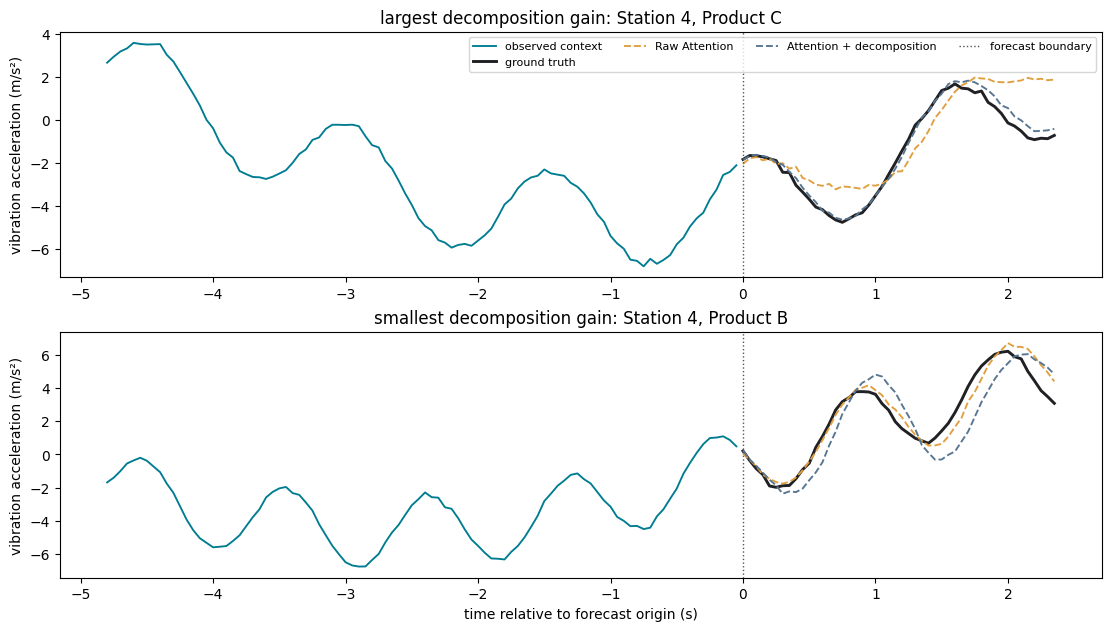

In [12]:
study.train("Attention + decomposition")
report.publish("2.3", figures.decomposition_ablation(study))


## 3. Mix by Temporal Delay


### Delay scores (supplied)


In [ ]:
def delay_scores(queries, keys):

    queries = queries - queries.mean(-1, keepdim=True)
    keys = keys - keys.mean(-1, keepdim=True)
    spectrum = torch.fft.rfft(queries, dim=-1) * torch.fft.rfft(keys, dim=-1).conj()
    return torch.fft.irfft(spectrum, n=queries.shape[-1], dim=-1).mean((1, 2))


In [ ]:

example = torch.tensor([1., 3., 1., 3.]).reshape(1, 1, 1, 4)
scores = pd.DataFrame({"delay": range(4),
                       "delay_scores (FFT)": delay_scores(example, example).flatten().tolist(),
                       "direct circular correlation": [4., -4., 4., -4.]})
display(scores.round(6))

assert design.check_delay_scores(delay_scores)
design.register_components(delay_scores=delay_scores)
report.publish("3.1", scores)


,delay,delay_scores (FFT),direct circular correlation
0,0,4.0,4.0
1,1,-4.0,-4.0
2,2,4.0,4.0
3,3,-4.0,-4.0


FFT delay-score checks passed.
Output 3.1


,delay,delay_scores (FFT),direct circular correlation
0,0,4.0,4.0
1,1,-4.0,-4.0
2,2,4.0,4.0
3,3,-4.0,-4.0


### Delay aggregation


In [ ]:
def aggregate_delays(values, delays, weights):
    length = values.shape[-1]
    positions = torch.arange(length, device=values.device)
    # source[b, j, t] = (t - delay_j) mod L; gather along time for each delay, then blend.
    source = (positions[None, None, :] - delays[:, :, None]) % length      # [B,K,L]
    index = source[:, :, None, None, :].expand(-1, -1, *values.shape[1:3], -1)
    shifted = values[:, None].expand(-1, delays.shape[1], -1, -1, -1).gather(-1, index)
    return (shifted * weights[:, :, None, None, None]).sum(1)


In [ ]:
values = torch.tensor([10., 20., 30., 40.]).reshape(1, 1, 1, 4)
mixed = aggregate_delays(values, torch.tensor([[1, 3]]), torch.tensor([[.75, .25]]))
aggregated = pd.DataFrame({"position": range(4),
                           "your aggregated value": mixed.flatten(),
                           "expected": [35., 15., 25., 25.]})
display(aggregated.round(6))

assert design.check_aggregation(aggregate_delays)
design.register_components(aggregate=aggregate_delays)


,position,your aggregated value,expected
0,0,35.0,35.0
1,1,15.0,15.0
2,2,25.0,25.0
3,3,25.0,25.0


Delay-aggregation checks passed.


### Delay mixer (supplied)

`DelayMixer` applies the full sequence: it projects the context into q/k/v features, calls the
supplied scorer, selects useful delays, and calls your aggregation function to combine the
shifted values.


In [17]:
class DelayMixer(nn.Module):
    def __init__(self, d, heads, delay_score_fn, aggregate_fn, min_delay=8, max_delay=48):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads, self.min_delay, self.max_delay = heads, min_delay, max_delay
        self.delay_score_fn, self.aggregate_fn = delay_score_fn, aggregate_fn
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.raw_temperature = nn.Parameter(torch.tensor(0.5413248546))

    @property
    def temperature(self):
        return F.softplus(self.raw_temperature) + 1e-6

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).permute(0, 2, 3, 1)
                   for layer in (self.query, self.key, self.value))  # [B,h,d_h,L]
        scores = self.delay_score_fn(q, k)      # [B,L]
        lo, hi = self.min_delay, min(self.max_delay, length - 1)
        band = scores[:, lo:hi + 1]
        top_k = min(math.ceil(2 * math.log(length)), band.shape[-1])
        selected, indices = band.topk(top_k, dim=-1)
        delays = indices + lo                  # [B,K]
        weights = (selected / self.temperature).softmax(-1)  # [B,K]
        mixed = self.aggregate_fn(v, delays, weights)         # [B,h,d_h,L]
        return self.out(mixed.permute(0, 3, 1, 2).reshape(batch, length, width))


### Output 3.2 — Signal-level recurrence diagnostic


Output 3.2


,station,product,expected delay (samples),nearest integer delay,residual signal correlation
0,2,Product A,16.135,16,0.896
1,2,Product A,32.269,32,0.897


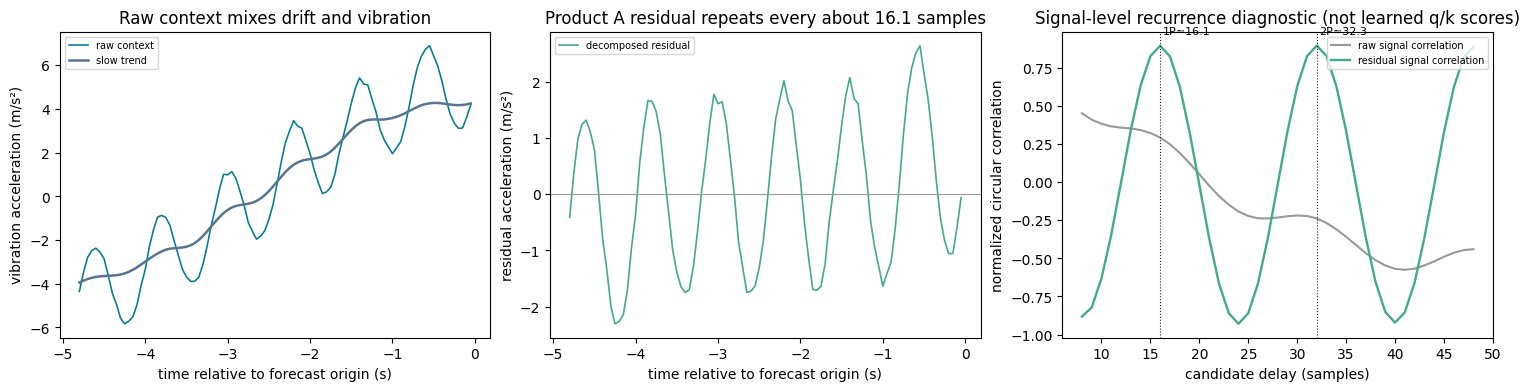

In [18]:
recurrence = figures.delay_recurrence(study)
report.publish("3.2", recurrence)


## 4. Compare Designs and Deploy

| Cell below                                                                    | Output |
| ----------------------------------------------------------------------------- | ------ |
| fit the two remaining models; comparison table and contrasting forecast cases | 4.1    |
| error along the 48-step horizon                                               | 4.2    |
| selected models and their validation/test results                             | 4.3    |


Model assembly and gradient checks passed (4 setting(s): raw/attention, raw/delay, decomposed/attention, decomposed/delay).
Raw delay mixer: 6000 steps, 92.6s, 368370 parameters, best established-validation MSE 0.051 (m/s²)² -- same physical units as the report tables below
Raw delay mixer: saved raw-delay-mixer-full-data0-model0-4864d9a7efa3.pt
Autoformer-inspired: 6000 steps, 111.6s, 373026 parameters, best established-validation MSE 0.039 (m/s²)² -- same physical units as the report tables below
Autoformer-inspired: saved autoformer-inspired-full-data0-model0-c5f6a128647a.pt
Output 4.1


,model,established stations RMSE (m/s²),established stations MSE (m/s²)²,"established stations, Product A RMSE","established stations, Product B RMSE","established stations, Product C RMSE",held-out station 4 RMSE (m/s²),held-out station 4 MSE (m/s²)²,"held-out station 4, Product A RMSE","held-out station 4, Product B RMSE","held-out station 4, Product C RMSE",parameters,fit seconds
0,Raw Attention,0.439,0.192,0.415,0.478,0.420,0.624,0.390,0.643,0.583,0.646,368368,75.604
1,Raw delay mixer,0.225,0.051,0.209,0.214,0.250,0.331,0.109,0.393,0.282,0.307,368370,92.641
2,Attention + decomposition,0.312,0.097,0.293,0.352,0.286,0.462,0.213,0.404,0.530,0.442,373024,93.476
3,Autoformer-inspired,0.197,0.039,0.224,0.180,0.185,0.244,0.059,0.277,0.217,0.232,373026,111.570


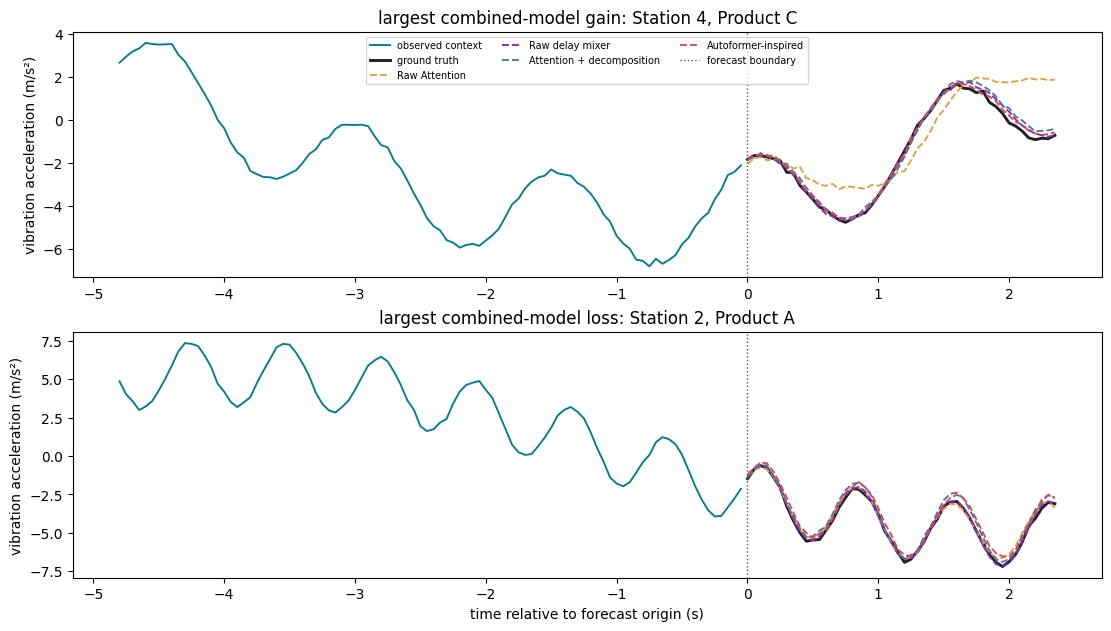

,case,station,product,model,window RMSE (m/s²)
0,largest combined-model gain,4,Product C,Raw Attention,1.300
1,largest combined-model gain,4,Product C,Raw delay mixer,0.187
2,largest combined-model gain,4,Product C,Attention + decomposition,0.279
3,largest combined-model gain,4,Product C,Autoformer-inspired,0.160
4,largest combined-model loss,2,Product A,Raw Attention,0.248
5,largest combined-model loss,2,Product A,Raw delay mixer,0.117
6,largest combined-model loss,2,Product A,Attention + decomposition,0.349
7,largest combined-model loss,2,Product A,Autoformer-inspired,0.407


In [ ]:
# Supplied unified 2×2 design.
class IdentitySplit(nn.Module):
    def forward(self, x):
        return x, torch.zeros_like(x)

class EncoderBlock(nn.Module):
    def __init__(self, d, heads, mixing, kernel, decomposition_type,
                 delay_score_fn, aggregate_fn, dropout):
        super().__init__()
        self.mix = (DelayMixer(d, heads, delay_score_fn, aggregate_fn)
                    if mixing == "delay" else DenseAttention(d, heads))
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        split = decomposition_type if decomposition_type is not None else lambda _: IdentitySplit()
        self.strip1, self.strip2 = split(kernel), split(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class AutoformerInspiredForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 mixing="attention", representation="raw", kernel=25, dropout=0.1,
                 decomposition_type=None, delay_score_fn=None, aggregate_fn=None):
        super().__init__()
        if representation not in {"raw", "decomposed"}:
            raise ValueError("representation must be 'raw' or 'decomposed'")
        self.split = (decomposition_type(kernel) if representation == "decomposed"
                      else IdentitySplit())
        self.trend_head = nn.Linear(context, horizon) if representation == "decomposed" else None
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock(
            d, heads, mixing, kernel, decomposition_type, delay_score_fn, aggregate_fn, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        trend_forecast = 0 if self.trend_head is None else self.trend_head(trend.squeeze(-1))
        return seasonal_forecast + trend_forecast

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]

    @property
    def delay_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DelayMixer)]

assert design.check_assembly(AutoformerInspiredForecaster)
design.register_components(forecaster_type=AutoformerInspiredForecaster)
study.train("Raw delay mixer")
study.train("Autoformer-inspired")
cases = figures.contrasting_forecasts(study)
report.publish("4.1", report.comparison(study, [
    "Raw Attention", "Raw delay mixer", "Attention + decomposition", "Autoformer-inspired"]))
display(cases.round(3))


Output 4.2


,model,population,horizon,MSE,RMSE (m/s²)
0,Period-routed ridge,established,1,0.013,0.112
1,Period-routed ridge,established,2,0.011,0.107
2,Period-routed ridge,established,3,0.014,0.118
3,Period-routed ridge,established,4,0.014,0.118
4,Period-routed ridge,established,5,0.015,0.121
...,...,...,...,...,...
475,Autoformer-inspired,held-out,44,0.105,0.324
476,Autoformer-inspired,held-out,45,0.114,0.338
477,Autoformer-inspired,held-out,46,0.111,0.333
478,Autoformer-inspired,held-out,47,0.115,0.340


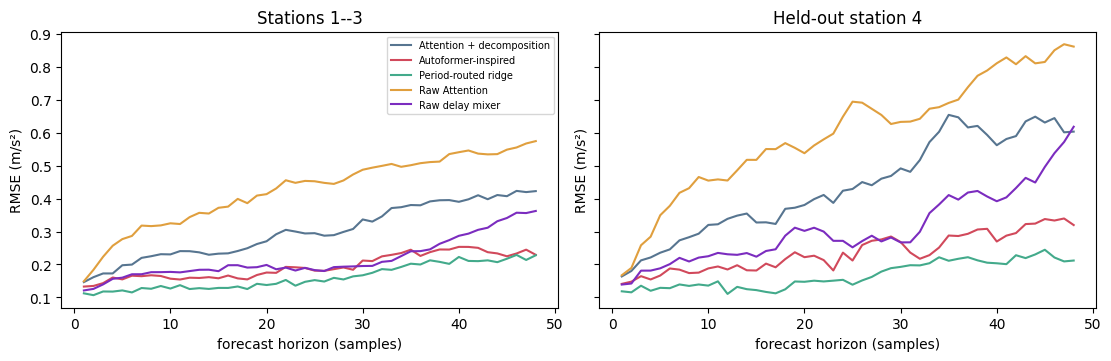

In [ ]:
report.publish("4.2", figures.horizon_figure(study, [
    "Period-routed ridge", "Raw Attention", "Raw delay mixer",
    "Attention + decomposition", "Autoformer-inspired"]))


### Choose the deployment models (Response 4)

| Cell below                               | Output |
| ---------------------------------------- | ------ |
| enter both choices                       | —      |
| validation/test results for both choices | 4.3    |


In [ ]:
# Validation-only decision summary.
display(report.deployment_summary(study).round(3))


,model,established validation RMSE (m/s²),established validation MSE (m/s²)²,held-out validation RMSE (m/s²),held-out validation MSE (m/s²)²,parameters,fit seconds
0,Shared ridge,0.767,0.588,0.876,0.767,4608,0.003
1,Sensor-specific ridge,0.768,0.590,NaN,NaN,13824,0.085
2,Period-routed ridge,0.166,0.028,0.173,0.030,59904,0.014
3,Raw Attention,0.439,0.192,0.624,0.390,368368,75.604
4,Attention + decomposition,0.312,0.097,0.462,0.213,373024,93.476
5,Raw delay mixer,0.225,0.051,0.331,0.109,368370,92.641
6,Autoformer-inspired,0.197,0.039,0.244,0.059,373026,111.570


In [ ]:
summary = report.deployment_summary(study)
col = lambda key: next(c for c in summary.columns if key in c and "MSE" in c)
pick = lambda key: summary.loc[summary[col(key)].idxmin(), "model"]
choices = {
    "established": pick("established validation"),
    "held-out": pick("held-out validation"),
}
print(choices)
display(study.select_for_test(choices))

{'established': 'Period-routed ridge', 'held-out': 'Period-routed ridge'}


,population,model
0,established,Period-routed ridge
1,held-out,Period-routed ridge


In [ ]:
report.publish("4.3", study.selected_test_table())


Output 4.3


,population,model,validation MSE,validation RMSE (m/s²),test MSE,test RMSE (m/s²)
0,established,Period-routed ridge,0.028,0.166,0.026,0.161
1,held-out,Period-routed ridge,0.030,0.173,0.033,0.183


Download the Result folder:


In [ ]:
%cd /kaggle/working

/kaggle/working


In [ ]:
!zip -r results.zip results

  adding: results/ (stored 0%)
  adding: results/design/ (stored 0%)
  adding: results/design/3.2.tex (deflated 33%)
  adding: results/design/2.3.tex (deflated 69%)
  adding: results/design/3.2-1.pdf (deflated 24%)
  adding: results/design/2.1.csv (deflated 28%)
  adding: results/design/4.3.csv (deflated 35%)
  adding: results/design/4.2.csv (deflated 68%)
  adding: results/design/2.2-1.pdf (deflated 32%)
  adding: results/design/2.1.tex (deflated 33%)
  adding: results/design/1.3.csv (deflated 35%)
  adding: results/design/4.1.tex (deflated 59%)
  adding: results/design/4.2.tex (deflated 87%)
  adding: results/design/1.2.tex (deflated 57%)
  adding: results/design/1.2.csv (deflated 56%)
  adding: results/design/4.3.tex (deflated 41%)
  adding: results/design/2.1-1.pdf (deflated 20%)
  adding: results/design/1.3.tex (deflated 48%)
  adding: results/design/4.1.csv (deflated 51%)
  adding: results/design/2.3-1.pdf (deflated 24%)
  adding: results/design/1.3-1.pdf (deflated 20%)
  adding:

In [ ]:
!ls -lh results.zip

-rw-r--r-- 1 root root 362K Oct  1 07:36 results.zip


In [ ]:
from IPython.display import FileLink
FileLink("results.zip")

/kaggle/working/results.zip